In [ ]:
import warnings; warnings.filterwarnings('ignore')
import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, accuracy_score)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
df_raw = pd.read_csv('Stores.csv')
print(df_raw.shape)
df_raw.head()

(118, 7)


,Store Number,AreaStore,Property,Type,Old/New,Checkout Number,Revenue
0,1,2100.0,Owned,Hyper,New,6.0,"45,072,000"
1,2,1290.0,Cooperate,Extra,New,5.0,"7,416,000"
2,3,500.0,Rental,Express,New,NaN,"8,592,000"
3,4,2000.0,Owned,Hyper,New,9.0,"48,415,500"
4,5,220.0,Rental,Express,Old,2.0,"3,345,500"


In [ ]:
df = df_raw.copy()
print(df.dtypes, '\n')
print('Missing value per kolom:'); print(df.isna().sum(), '\n')
for c in ['Property', 'Type', 'Old/New']:
    print(c, '->', df[c].unique().tolist())

Store Number         int64
AreaStore          float64
Property            object
Type                object
Old/New             object
Checkout Number    float64
Revenue             object
dtype: object 

Missing value per kolom:
Store Number        0
AreaStore           0
Property            0
Type                0
Old/New             0
Checkout Number    12
Revenue             0
dtype: int64 

Property -> ['Owned', 'Cooperate', 'Rental', 'Owned ', 'Rental ', 'Rental/Cooperate', 'Cooperate ']
Type -> ['Hyper', 'Extra', 'Express']
Old/New -> ['New', 'Old', 'New ', 'Old ']


In [ ]:
df['Revenue'] = df['Revenue'].str.replace(',', '').astype(float)
for c in ['Property', 'Type', 'Old/New']:
    df[c] = df[c].str.strip()
print('Setelah dibersihkan:')
for c in ['Property', 'Type', 'Old/New']:
    print(c, '->', df[c].value_counts().to_dict())
print('Duplikat:', df.duplicated().sum())
df.describe().round(0)

Setelah dibersihkan:
Property -> {'Owned': 41, 'Rental': 33, 'Cooperate': 29, 'Rental/Cooperate': 15}
Type -> {'Express': 55, 'Extra': 36, 'Hyper': 27}
Old/New -> {'New': 102, 'Old': 16}
Duplikat: 0


,Store Number,AreaStore,Checkout Number,Revenue
count,118.0,118.0,106.0,118.0
mean,60.0,1374.0,5.0,22998051.0
std,34.0,1092.0,3.0,20514521.0
min,1.0,82.0,1.0,2336000.0
25%,30.0,530.0,3.0,9021375.0
50%,60.0,1000.0,4.0,13584750.0
75%,89.0,1888.0,6.0,31050500.0
max,118.0,5600.0,14.0,100083000.0


In [ ]:
THRESHOLD = df['Revenue'].median()
df['Layak'] = (df['Revenue'] > THRESHOLD).astype(int)
print(f'Threshold (median Revenue): Rp {THRESHOLD:,.0f}')
print(df['Layak'].value_counts())

Threshold (median Revenue): Rp 13,584,750
Layak
1    59
0    59
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

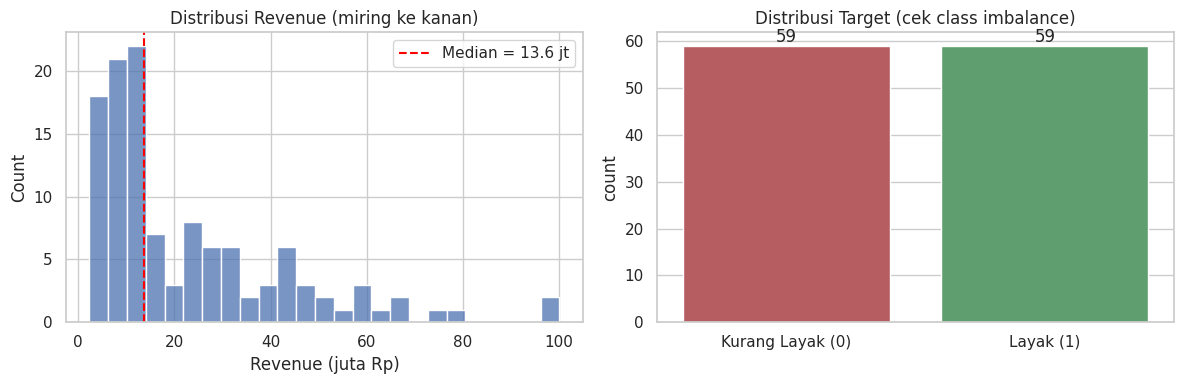

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Revenue']/1e6, bins=25, ax=ax[0], color='#4C72B0')
ax[0].axvline(THRESHOLD/1e6, color='red', ls='--', label=f'Median = {THRESHOLD/1e6:.1f} jt')
ax[0].set(title='Distribusi Revenue (miring ke kanan)', xlabel='Revenue (juta Rp)'); ax[0].legend()
sns.countplot(x='Layak', data=df, ax=ax[1], palette=['#C44E52', '#55A868'])
ax[1].set(title='Distribusi Target (cek class imbalance)', xticklabels=['Kurang Layak (0)', 'Layak (1)'], xlabel='')
for p in ax[1].patches: ax[1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.tight_layout(); plt.savefig('figures/01_target_dist.png', dpi=150); plt.show()

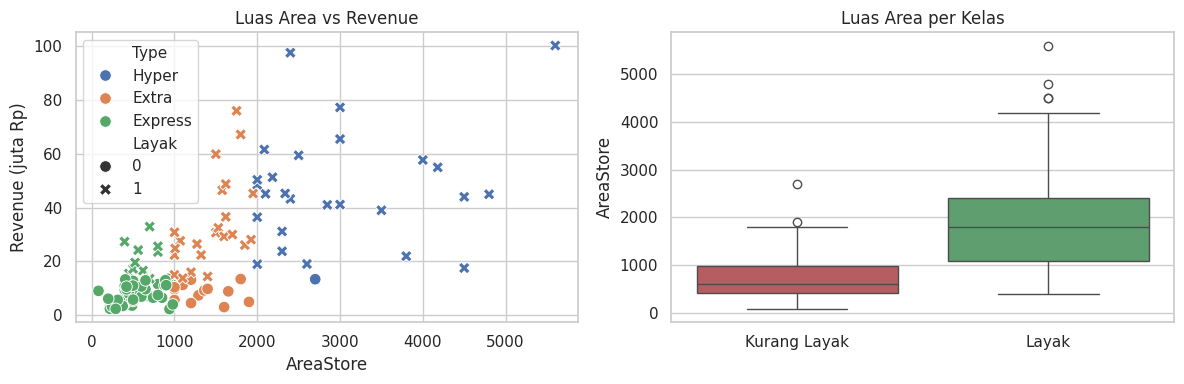

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x='AreaStore', y=df['Revenue']/1e6, hue='Type', style='Layak', s=70, ax=ax[0])
ax[0].set(title='Luas Area vs Revenue', ylabel='Revenue (juta Rp)')
sns.boxplot(data=df, x='Layak', y='AreaStore', ax=ax[1], palette=['#C44E52', '#55A868'])
ax[1].set(title='Luas Area per Kelas', xticklabels=['Kurang Layak', 'Layak'], xlabel='')
plt.tight_layout(); plt.savefig('figures/02_area_revenue.png', dpi=150); plt.show()

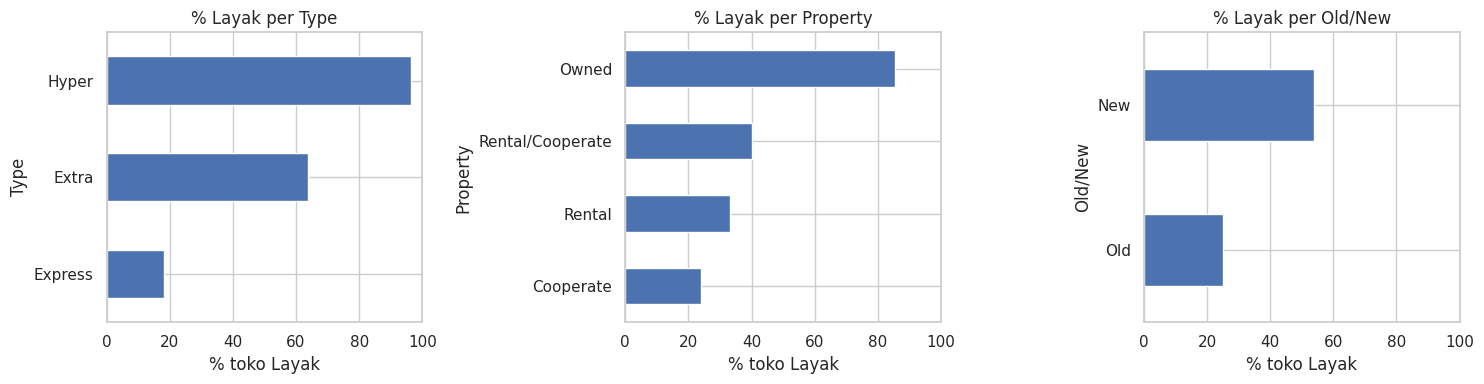

         AreaStore  Checkout Number     Revenue
Type                                           
Express      500.0              3.0   9646500.0
Extra       1400.0              6.0  22380500.0
Hyper       2600.0              8.0  44911000.0


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ['Type', 'Property', 'Old/New']):
    (df.groupby(c)['Layak'].mean()*100).sort_values().plot(kind='barh', ax=a, color='#4C72B0')
    a.set(title=f'% Layak per {c}', xlabel='% toko Layak', xlim=(0, 100))
plt.tight_layout(); plt.savefig('figures/03_categorical.png', dpi=150); plt.show()
print(df.groupby('Type')[['AreaStore', 'Checkout Number', 'Revenue']].median().round(0))

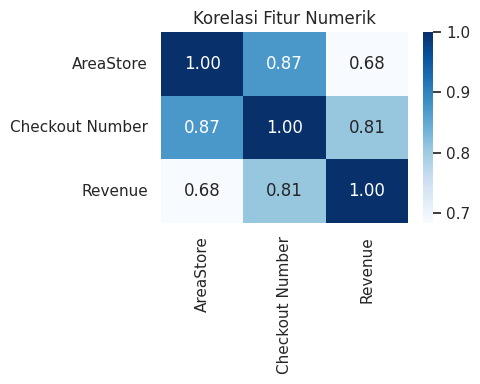

In [9]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[['AreaStore', 'Checkout Number', 'Revenue']].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Korelasi Fitur Numerik'); plt.tight_layout(); plt.savefig('figures/04_corr.png', dpi=150); plt.show()

In [10]:
NUM = ['AreaStore', 'Checkout Number']
CAT = ['Property', 'Type', 'Old/New']
X, y = df[NUM + CAT], df['Layak']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi Layak train/test:', y_train.mean().round(2), y_test.mean().round(2))

def build_pipeline(C=1.0, class_weight=None):
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', IterativeImputer(random_state=RANDOM_STATE)), ('scaler', StandardScaler())]), NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT)])
    return Pipeline([('prep', prep), ('clf', LogisticRegression(C=C, class_weight=class_weight, max_iter=1000, random_state=RANDOM_STATE))])

Train: (82, 5) | Test: (36, 5)
Proporsi Layak train/test: 0.5 0.5


In [11]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
rows = []
for C in [0.03, 0.1, 0.3, 1, 3, 10]:
    r = cross_validate(build_pipeline(C), X_train, y_train, cv=cv, scoring=['f1', 'roc_auc'])
    rows.append({'C': C, 'F1 (CV)': r['test_f1'].mean(), 'AUC (CV)': r['test_roc_auc'].mean()})
cv_table = pd.DataFrame(rows).round(3); print(cv_table)
BEST_C = float(cv_table.sort_values(['AUC (CV)', 'F1 (CV)'], ascending=False).iloc[0]['C'])
print('C terpilih:', BEST_C)

       C  F1 (CV)  AUC (CV)
0   0.03    0.778     0.862
1   0.10    0.776     0.867
2   0.30    0.767     0.871
3   1.00    0.741     0.862
4   3.00    0.736     0.849
5  10.00    0.733     0.826
C terpilih: 0.3


In [12]:
model = build_pipeline(C=BEST_C).fit(X_train, y_train)
print('Model terlatih.')
model

Model terlatih.


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   IterativeImputer(random_state=42)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['AreaStore',
                                                   'Checkout Number']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Property', 'Type',
                                                   'Old/New'])])),
                ('clf',
                 LogisticRegression(C=0.3, max_iter=1000, random_state=42))])

              precision    recall  f1-score   support

Kurang Layak       0.85      0.94      0.89        18
       Layak       0.94      0.83      0.88        18

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.89      0.89      0.89        36



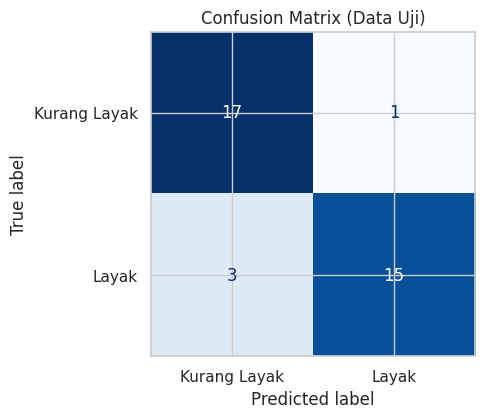

TN=17  FP=1  FN=3  TP=15


In [13]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=['Kurang Layak', 'Layak']))
cm = confusion_matrix(y_test, pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=['Kurang Layak', 'Layak']).plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Confusion Matrix (Data Uji)'); plt.tight_layout(); plt.savefig('figures/05_confusion.png', dpi=150); plt.show()
tn, fp, fn, tp = cm.ravel(); print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')

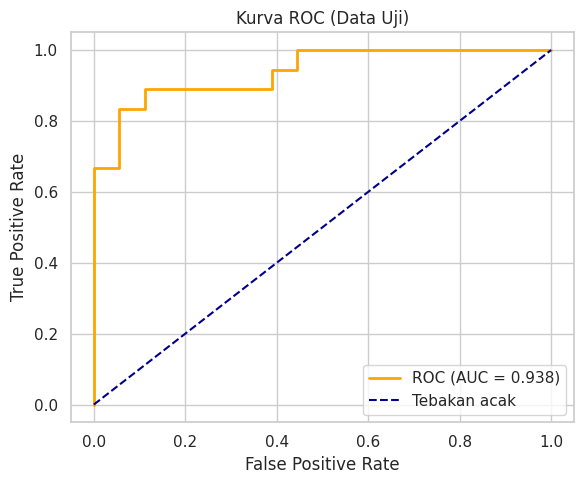

AUC data uji = 0.9383


In [14]:
fpr, tpr, _ = roc_curve(y_test, proba); auc = roc_auc_score(y_test, proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='orange', lw=2, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', color='darkblue', label='Tebakan acak')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('Kurva ROC (Data Uji)'); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig('figures/06_roc.png', dpi=150); plt.show()
print(f'AUC data uji = {auc:.4f}')

In [15]:
r = cross_validate(build_pipeline(BEST_C), X, y, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
cv_summary = {m: (r[f'test_{m}'].mean(), r[f'test_{m}'].std()) for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']}
pd.DataFrame(cv_summary, index=['mean', 'std']).T.round(3)

,mean,std
accuracy,0.824,0.068
precision,0.874,0.091
recall,0.766,0.121
f1,0.809,0.081
roc_auc,0.898,0.055


In [16]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= t).astype(int)
    rows.append({'threshold': t, 'precision': precision_score(y_test, p, zero_division=0),
                 'recall': recall_score(y_test, p), 'f1': f1_score(y_test, p), 'lokasi disetujui': int(p.sum())})
thr_table = pd.DataFrame(rows).round(3); print(thr_table)

   threshold  precision  recall     f1  lokasi disetujui
0        0.3      0.696   0.889  0.780                23
1        0.4      0.800   0.889  0.842                20
2        0.5      0.938   0.833  0.882                16
3        0.6      0.933   0.778  0.848                15
4        0.7      1.000   0.611  0.759                11
5        0.8      1.000   0.444  0.615                 8


In [17]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
base = build_pipeline(BEST_C)
smote_pipe = ImbPipeline([('prep', base.named_steps['prep']), ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)), ('clf', LogisticRegression(C=BEST_C, max_iter=1000, random_state=RANDOM_STATE))])
variants = {'Baseline (tanpa penyeimbangan)': build_pipeline(BEST_C),
            'class_weight="balanced"': build_pipeline(BEST_C, 'balanced'),
            'SMOTE': smote_pipe}
rows = []
for name, m in variants.items():
    r = cross_validate(m, X, y, cv=cv, scoring=['precision', 'recall', 'f1', 'roc_auc'])
    rows.append({'Varian': name, 'Precision': r['test_precision'].mean(), 'Recall': r['test_recall'].mean(),
                 'F1': r['test_f1'].mean(), 'AUC': r['test_roc_auc'].mean()})
imb_table = pd.DataFrame(rows).round(3); imb_table

,Varian,Precision,Recall,F1,AUC
0,Baseline (tanpa penyeimbangan),0.874,0.766,0.809,0.898
1,"class_weight=""balanced""",0.876,0.768,0.811,0.897
2,SMOTE,0.876,0.768,0.811,0.898


                    fitur  koefisien  odds_ratio
Property_Rental/Cooperate     -0.433       0.649
              Old/New_Old     -0.096       0.908
          Property_Rental     -0.018       0.982
               Type_Extra      0.290       1.336
               Type_Hyper      0.358       1.431
                AreaStore      0.697       2.007
          Checkout Number      0.723       2.061
           Property_Owned      0.753       2.123


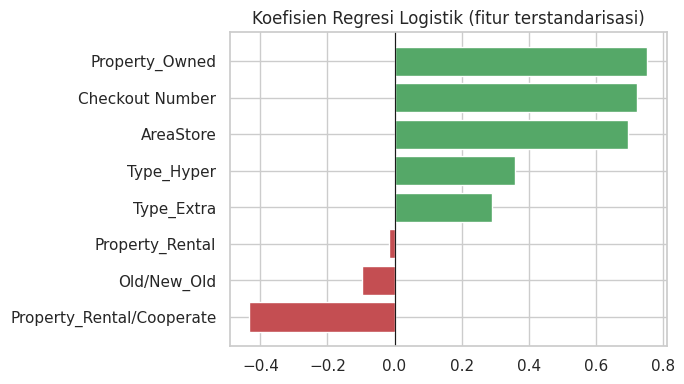

In [19]:
feat_names = model.named_steps['prep'].get_feature_names_out()
coef = pd.DataFrame({'fitur': [n.split('__')[1] for n in feat_names], 'koefisien': model.named_steps['clf'].coef_[0]})
coef['odds_ratio'] = np.exp(coef['koefisien'])
coef = coef.sort_values('koefisien'); print(coef.round(3).to_string(index=False))
plt.figure(figsize=(7, 4))
plt.barh(coef['fitur'], coef['koefisien'], color=['#C44E52' if v < 0 else '#55A868' for v in coef['koefisien']])
plt.axvline(0, color='k', lw=0.8); plt.title('Koefisien Regresi Logistik (fitur terstandarisasi)')
plt.tight_layout(); plt.savefig('figures/07_coef.png', dpi=150); plt.show()

In [18]:
final_model = build_pipeline(BEST_C).fit(X, y)
joblib.dump(final_model, 'model/lokasi_model.joblib')
meta = {'threshold_revenue': float(THRESHOLD), 'best_C': BEST_C, 'n_data': int(len(df)),
        'categories': {c: sorted(df[c].unique().tolist()) for c in CAT},
        'ranges': {'AreaStore': [float(df['AreaStore'].min()), float(df['AreaStore'].max())],
                   'Checkout Number': [float(df['Checkout Number'].min()), float(df['Checkout Number'].max())]},
        'cv_metrics': {k: {'mean': float(v[0]), 'std': float(v[1])} for k, v in cv_summary.items()},
        'test_metrics': {'accuracy': float(accuracy_score(y_test, pred)), 'precision': float(precision_score(y_test, pred)),
                         'recall': float(recall_score(y_test, pred)), 'f1': float(f1_score(y_test, pred)), 'auc': float(auc),
                         'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}}
json.dump(meta, open('model/metadata.json', 'w'), indent=2)
# uji muat ulang
loaded = joblib.load('model/lokasi_model.joblib')
contoh = pd.DataFrame([{'AreaStore': 2000, 'Checkout Number': 8, 'Property': 'Owned', 'Type': 'Hyper', 'Old/New': 'New'}])
print('Contoh prediksi (Hyper 2000 m2, 8 kasir, milik sendiri):', loaded.predict_proba(contoh)[0, 1].round(3))

Contoh prediksi (Hyper 2000 m2, 8 kasir, milik sendiri): 0.931
